# 03 · What changes when I move the cutoff?

I loaded the saved ANN and tried different thresholds on the validation window. This let me measure the review workload without retraining the model.

In [2]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
project = Path("/content/drive/MyDrive/Colab Notebooks/Project 01: Intelligent Financial Fraud Detection")
# Use the checkpoint and metrics from the same run.
run_id = "20261121T162317186996Z"
weights_path = project / "Artifacts" / f"ann_{run_id}.pt"
metrics_path = project / "Artifacts" / f"metrics_{run_id}.csv"
csv_path = project / "Dataset" / "creditcard.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## The reference run

These are the held-out results for the run ID in the setup cell. I use the validation rows for the dashboard experiments below.

In [3]:
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from IPython.display import display

metrics = pd.read_csv(metrics_path).set_index("Model")
display(metrics[["PR-AUC", "Precision", "Recall", "Alerts", "True alerts", "False alerts", "Missed fraud"]].round(4))

,PR-AUC,Precision,Recall,Alerts,True alerts,False alerts,Missed fraud
Model,,,,,,,
ANN,0.7733,0.9231,0.6923,39,36,3,16
Logistic regression,0.7104,0.9429,0.6346,35,33,2,19
Boosted trees,0.7058,0.8250,0.6346,40,33,7,19


## Restoring the scorer

I load the original feature order, scaler and weights, then turn off dropout for inference. Because I weighted the fraud class during training, I interpret the sigmoid output as a ranking score.

In [4]:
saved = torch.load(weights_path, map_location="cpu", weights_only=True)
features = saved["features"]
threshold = float(saved["threshold"])
if not np.isclose(threshold, metrics.loc["ANN", "Threshold"], rtol=0, atol=1e-12):
    raise ValueError("The checkpoint and metrics use different thresholds. Check the run ID.")

model = nn.Sequential(nn.Linear(len(features), 64), nn.ReLU(), nn.Dropout(0.2),
                      nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
model.load_state_dict(saved["state_dict"])
model.eval()  # Disable dropout when scoring.
mean = np.asarray(saved["mean"])
scale = np.asarray(saved["scale"])

@torch.inference_mode()
def score_transactions(rows):
    # Select the training columns in order. Class is never an input.
    values = rows.loc[:, features].to_numpy(dtype=np.float64)
    if not np.isfinite(values).all():
        raise ValueError("Each input feature must contain a finite number.")
    x = torch.from_numpy(((values - mean) / scale).astype("float32"))
    batches = [model(batch).flatten().sigmoid() for batch in x.split(4096)]
    return torch.cat(batches).numpy()

print(f"Saved ANN cutoff = {threshold:.10f}")

Saved ANN cutoff = 0.9998766184


In [5]:
# Reproduce notebook 02's time boundaries, keeping equal timestamps together.
transactions = pd.read_csv(csv_path).sort_values("Time", kind="stable")
times = transactions["Time"].to_numpy()
start, end = times[[int(0.70 * len(times)), int(0.85 * len(times))]]
validation = transactions.loc[(transactions.Time >= start) & (transactions.Time < end)].copy()
validation["score"] = score_transactions(validation)
labels = validation["Class"].to_numpy()
scores = validation["score"].to_numpy()
curve_precision, curve_recall, _ = precision_recall_curve(labels, scores)
print(f"Validation window: {len(validation):,} transactions, {int(labels.sum())} frauds.")

Validation window: 42,719 transactions, 56 frauds.


## Comparing review workloads

The saved cutoff is about 0.9998766. At full precision it produced 42 validation alerts, all fraud. At 0.99 I got 73 alerts and 47 frauds. Those five extra detections took 31 extra reviews. The table and red point show the cutoff currently selected.

,Reviews,Fraud caught,False alerts,Missed fraud,Precision,Recall
Saved cutoff,42,42,0,14,1.0,0.75
Selected cutoff,42,42,0,14,1.0,0.75


Selected cutoff = 0.9998766184


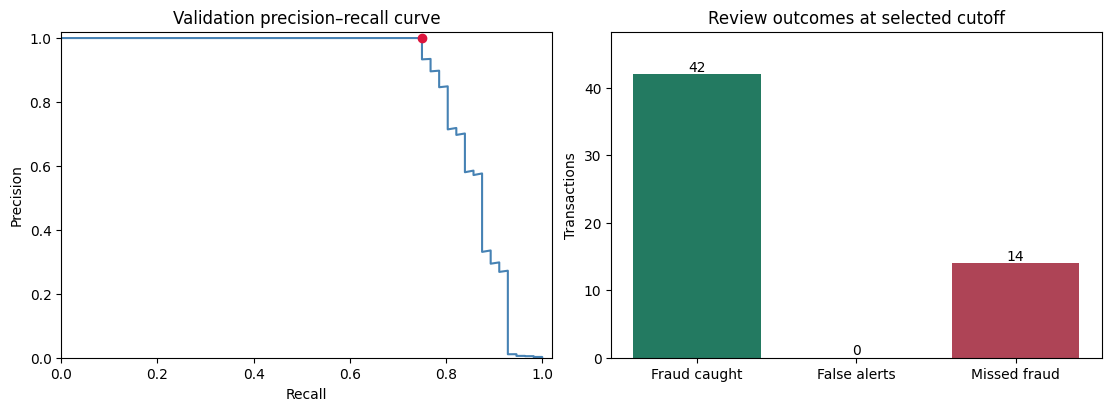

,Time,Amount,score,Class
223572,143434.000000,1.00,1.000000000,1
223618,143456.000000,1.00,1.000000000,1
230076,146179.000000,0.77,1.000000000,1
234574,148028.000000,0.00,1.000000000,1
238222,149582.000000,1.10,1.000000000,1
226814,144808.000000,667.55,0.999999881,1
229712,146022.000000,1.18,0.999999881,1
235616,148468.000000,0.76,0.999999881,1
235634,148476.000000,0.76,0.999999881,1
212644,138942.000000,727.91,0.999999762,1


In [6]:
# @title Validation dashboard
use_saved_threshold = True # @param {type:"boolean"}
custom_cutoff = 0.999 # @param {type:"number"}
cutoff = threshold if use_saved_threshold else custom_cutoff
if not 0 <= cutoff <= 1:
    raise ValueError("Enter a cutoff between 0 and 1.")

def review_summary(cut):
    # A transaction at the exact cutoff is included in the queue.
    flagged = scores >= cut
    tp = int(((labels == 1) & flagged).sum())
    fp = int(flagged.sum()) - tp
    fn = int(labels.sum()) - tp
    return {"Reviews": tp + fp, "Fraud caught": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn)}

current = review_summary(cutoff)
display(pd.DataFrame([review_summary(threshold), current], index=["Saved cutoff", "Selected cutoff"]).round(4))
print(f"Selected cutoff = {cutoff:.10f}")

fig, (pr, counts) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
pr.plot(curve_recall, curve_precision, color="steelblue")
if current["Reviews"]:
    pr.scatter(current["Recall"], current["Precision"], color="crimson", zorder=3)
pr.set(xlabel="Recall", ylabel="Precision", title="Validation precision–recall curve",
       xlim=(0, 1.02), ylim=(0, 1.02))
categories = ["Fraud caught", "False alerts", "Missed fraud"]
bars = counts.bar(categories, [current[key] for key in categories], color=["#237a61", "#df9132", "#ae4456"])
counts.bar_label(bars)
counts.margins(y=0.15)
counts.set(ylabel="Transactions", title="Review outcomes at selected cutoff")
plt.show()

# Ground truth is shown here for retrospective review.
queue = validation.loc[validation.score >= cutoff, ["Time", "Amount", "score", "Class"]]
display(queue.nlargest(10, "score").style.format({"score": "{:.9f}", "Amount": "{:.2f}"}))

## Checking one payment

I pass just the 30 input features to the scorer. Once it has made the decision, I look at the historical label to see whether the flag was justified.

In [14]:
row_position = 333 # @param {type:"integer"}
if not 0 <= row_position < len(validation):
    raise ValueError(f"Choose a row from 0 to {len(validation)-1}.")
example = validation.iloc[[row_position]]
risk = float(score_transactions(example[features])[0])
print(f"Amount {example.Amount.iloc[0]:.2f} | score {risk:.9f} | send for review: {risk >= threshold}")
print(f"Historical label (shown after scoring): {int(example.Class.iloc[0])}")

Amount 197.22 | score 0.000002250 | send for review: False
Historical label (shown after scoring): 0
